# Retail Dynamics Weekly Sales Forecasting

**Sections**
1. Setup
2. Data preparation and EDA (Task 1)
3. Modelling and analysis (Tasks 2 and 3)

## 1. Setup

In [1]:
# Import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_score, cross_val_predict, train_test_split

# Set the main chart colour
BAR_COLOUR = '#4C72B0'

# Set extra colours for the modelling charts
OTHER_COLOUR = '#B0B0B0'
SHORT_COLOUR = '#DD8452'

### Load the data


In [2]:
# Load the data and show the first 5 rows
df = pd.read_csv("data/customer_data.csv")
df.head()

,StoreID,Week,Price,Display,Media,Sales
0,S1115,2,8.74,No,0,295
1,S1076,2,9.31,N,0,234
2,S1102,3,10.53,no,0,237
3,S1057,8,13.45,No,1,225
4,S1102,6,9.01,no,0,233


## 2. Data preparation and EDA

### 2.1 Brief Overview

In [3]:
# Print the number of rows and columns
print(df.shape)

# Print the table showing all the information
df.info()

(1500, 6)
,<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 1500 entries, 0 to 1499
,Data columns (total 6 columns):
, #   Column   Non-Null Count  Dtype  
,---  ------   --------------  -----  
, 0   StoreID  1500 non-null   object 
, 1   Week     1500 non-null   int64  
, 2   Price    1500 non-null   float64
, 3   Display  1500 non-null   object 
, 4   Media    1500 non-null   int64  
, 5   Sales    1500 non-null   int64  
,dtypes: float64(1), int64(3), object(2)
,memory usage: 70.4+ KB


In [4]:
# Calculate the number of missing values per column
df.isna().sum()

StoreID    0
Week       0
Price      0
Display    0
Media      0
Sales      0
dtype: int64

### 2.2 Data-quality checks

In [5]:
# Count duplicate store and week pairs
print('Duplicate store-weeks:', df.duplicated(subset=['StoreID', 'Week']).sum())

# Check how many weeks each store has
print('Weeks per store:', df.groupby('StoreID').size().unique())

# Show the summary statistics for the number columns
df[['Week', 'Price', 'Media', 'Sales']].describe()

Duplicate store-weeks: 0
,Weeks per store: [10]


,Week,Price,Media,Sales
count,1500.000000,1500.000000,1500.000000,1500.000000
mean,5.500000,11.984760,0.252667,235.653333
std,2.873239,2.163133,0.434686,42.898874
min,1.000000,6.500000,0.000000,120.000000
25%,3.000000,10.517500,0.000000,206.000000
50%,5.500000,11.970000,0.000000,234.000000
75%,8.000000,13.480000,1.000000,264.000000
max,10.000000,17.250000,1.000000,360.000000


In [6]:
# Count how many rows sit at the lowest and highest price
print('Store-weeks at exactly $6.50: ', (df['Price'] == df['Price'].min()).sum())
print('Store-weeks at exactly $17.25:', (df['Price'] == df['Price'].max()).sum())

Store-weeks at exactly $6.50:  10
,Store-weeks at exactly $17.25: 8


### 2.3 Fixing the Display column

In [7]:
# Show all the different Display values
df['Display'].value_counts()

Display
No     364
N      337
no     333
Y      166
yes    155
Yes    145
Name: count, dtype: int64

In [8]:
# Change every Display value to either Yes or No
df['Display'] = df['Display'].str.lower().str[0].map({'y': 'Yes', 'n': 'No'})

# Check that only Yes and No are left
df['Display'].value_counts()

Display
No     1034
Yes     466
Name: count, dtype: int64

### 2.4 How are weekly sales distributed?

count    1500.000000
,mean      235.653333
,std        42.898874
,min       120.000000
,25%       206.000000
,50%       234.000000
,75%       264.000000
,max       360.000000
,Name: Sales, dtype: float64


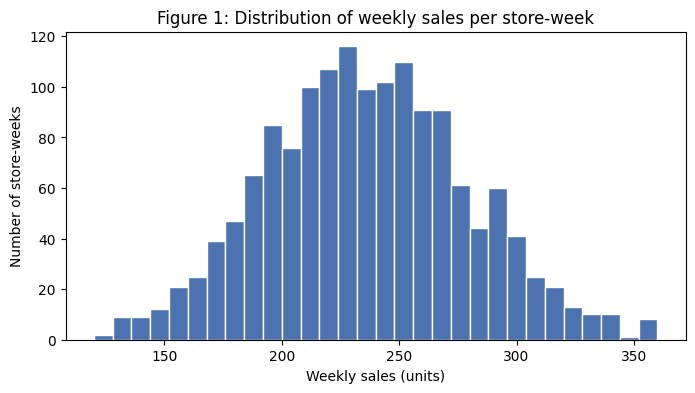

In [9]:
# Print the summary statistics for Sales
print(df['Sales'].describe())

# Plot a histogram of weekly sales
plt.figure(figsize=(8, 4))
plt.hist(df['Sales'], bins=30, color=BAR_COLOUR, edgecolor='white')
plt.xlabel('Weekly sales (units)')
plt.ylabel('Number of store-weeks')
plt.title('Figure 1: Distribution of weekly sales per store-week')
plt.show()

In [10]:
# Calculate the average sales for each store
store_avg = df.groupby('StoreID')['Sales'].mean()

# Print the lowest, highest and spread of store averages
print('Lowest store average: ', round(store_avg.min(), 1))
print('Highest store average:', round(store_avg.max(), 1))
print('Std dev between stores:', round(store_avg.std(), 1))

Lowest store average:  179.5
,Highest store average: 285.5
,Std dev between stores: 21.7


### 2.5 Sales under different conditions

In [11]:
# Calculate average sales with and without a display
df.groupby('Display')['Sales'].agg(['mean', 'count']).round(1)

,mean,count
Display,,
No,223.7,1034
Yes,262.1,466


In [12]:
# Calculate average sales with and without media
df.groupby('Media')['Sales'].agg(['mean', 'count']).round(1)

,mean,count
Media,,
0,228.4,1121
1,257.2,379


In [13]:
# Find the median price
price_median = df['Price'].median()
print('Median price: $', price_median)

# Label each row as a Higher or Lower price
df['PriceBand'] = df['Price'].apply(lambda p: 'Higher' if p > price_median else 'Lower')

# Calculate average sales for higher and lower prices
df.groupby('PriceBand')['Sales'].agg(['mean', 'count']).round(1)

Median price: $ 11.97


,mean,count
PriceBand,,
Higher,220.6,748
Lower,250.7,752


In [14]:
# Calculate average sales for each week
df.groupby('Week')['Sales'].mean().round(1)

Week
1     241.2
2     235.4
3     237.0
4     235.9
5     242.5
6     236.1
7     232.6
8     226.3
9     230.4
10    239.0
Name: Sales, dtype: float64

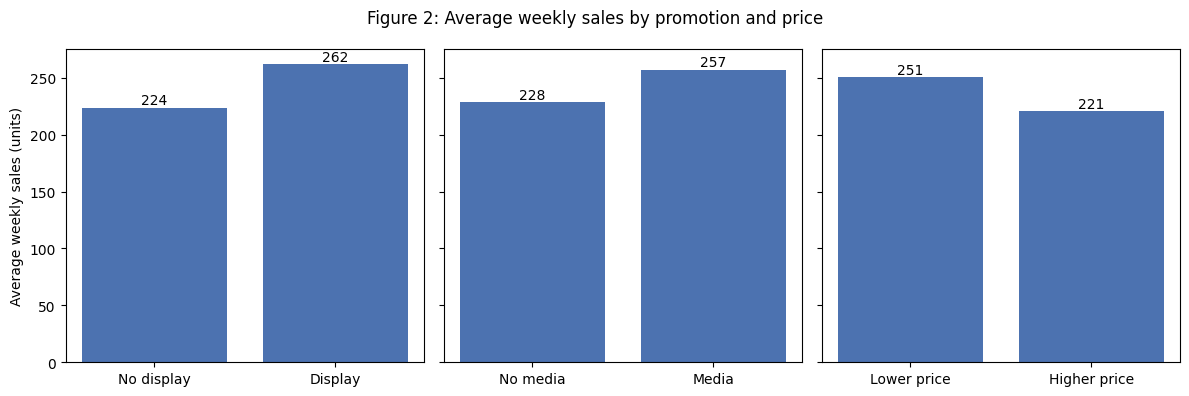

In [15]:
# Calculate the averages for each condition
display_means = df.groupby('Display')['Sales'].mean()
media_means = df.groupby('Media')['Sales'].mean()
price_means = df.groupby('PriceBand')['Sales'].mean()

# Create three charts side by side
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

# Plot the bars for each condition
axes[0].bar(['No display', 'Display'], [display_means['No'], display_means['Yes']], color=BAR_COLOUR)
axes[1].bar(['No media', 'Media'], [media_means[0], media_means[1]], color=BAR_COLOUR)
axes[2].bar(['Lower price', 'Higher price'], [price_means['Lower'], price_means['Higher']], color=BAR_COLOUR)

# Add the value above each bar
for ax in axes:
    for bar in ax.patches:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3,
                round(bar.get_height()), ha='center')

# Add the labels and title
axes[0].set_ylabel('Average weekly sales (units)')
fig.suptitle('Figure 2: Average weekly sales by promotion and price')
plt.tight_layout()
plt.show()

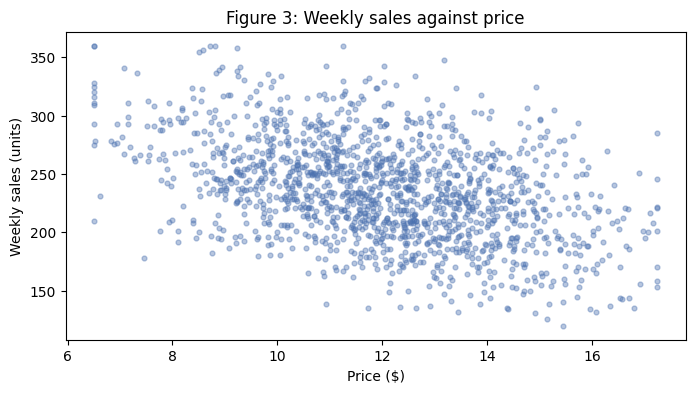

Price   -0.43
,Week    -0.05
,Media    0.29
,Sales    1.00
,Name: Sales, dtype: float64


In [16]:
# Plot price against sales
plt.figure(figsize=(8, 4))
plt.scatter(df['Price'], df['Sales'], s=12, alpha=0.4, color=BAR_COLOUR)
plt.xlabel('Price ($)')
plt.ylabel('Weekly sales (units)')
plt.title('Figure 3: Weekly sales against price')
plt.show()

# Print how strongly each column relates to Sales
print(df[['Price', 'Week', 'Media', 'Sales']].corr()['Sales'].round(2))

### 2.6 Do display and media work together?

In [17]:
# Calculate average sales for each Display and Media combination
combo = df.groupby(['Display', 'Media'])['Sales'].agg(['mean', 'count']).round(1)
combo

mean  count
Display Media              
No      0      216.5    779
        1      245.8    255
Yes     0      255.5    342
        1      280.6    124

### 2.7 Extra checks

In [18]:
# Calculate each store's average sales with and without a display
store_display = df.groupby(['StoreID', 'Display'])['Sales'].mean().unstack()

# Work out the difference for each store
store_lift = (store_display['Yes'] - store_display['No']).dropna()

# Print the results
print('Stores with both display and non-display weeks:', len(store_lift))
print('Average extra units with a display:', round(store_lift.mean(), 1))
print('Stores that sold more with a display:', round((store_lift > 0).mean() * 100), '%')

Stores with both display and non-display weeks: 146
,Average extra units with a display: 39.0
,Stores that sold more with a display: 94 %


In [19]:
# Check the average price in display and media weeks
print(df.groupby('Display')['Price'].mean().round(2))
print(df.groupby('Media')['Price'].mean().round(2))

Display
,No     11.91
,Yes    12.16
,Name: Price, dtype: float64
,Media
,0    11.98
,1    11.99
,Name: Price, dtype: float64


In [20]:
# Compare higher and lower price sales with and without a display
df.groupby(['Display', 'PriceBand'])['Sales'].mean().round(1).unstack()

PriceBand,Higher,Lower
Display,,
No,207.3,239.4
Yes,248.2,277.3


### 2.8 Findings So far

**Key patterns**
- **Display:** stores sold 262 units on average in weeks with a display, and 224 without. That's about 38 more units.
- **Media:** weeks with media averaged 257 units, compared to 228 without. About 29 more units.
- **Price:** when the price was above \$11.97, stores averaged 221 units. Below it, they averaged 251. So higher prices meant about 30 fewer units.

**Extra checks**
- Comparing each store against itself, a display added about 39 units, and 94% of stores sold more in their display weeks. So the display effect isn't just bigger stores using displays more.
- Display weeks weren't cheaper weeks (\$12.16 vs \$11.91 average price), and media weeks had the same average price as the rest. So the promotion effects aren't a price effect in disguise.
- Higher prices cut sales by about the same amount with or without a display (32 vs 29 units).

**Data quality:** the Display column had six different ways of writing Yes and No (No, N, no, Y, yes, Yes). We changed them all to just Yes or No.

**Hypotheses**
1. Weeks with a display sell about 38 more units than weeks without one (262 vs 224).
2. Weeks priced above \$11.97 sell about 30 fewer units than weeks priced below it (221 vs 251).

**Assumptions**
1. Each row is one store in one week, with no doubles. We checked this: there are no duplicate store-weeks and every store has 10 weeks.
2. The different Display spellings all mean the same thing. They're just typed differently, not different kinds of display.
3. Some prices sit exactly on \$6.50 (10 rows) and \$17.25 (8 rows), so it looks like prices were capped. We kept these rows, but the model can't say anything about prices outside that range.

**Follow-up questions**
1. Why do some stores sell around 100 more units a week than others? Is it location, store size, or something that isn't in this data?
2. When a store uses a display and media together, do the two just add up, or does one make the other work better?

### 2.9 Handover to modelling

In [21]:
# Change Display to 1 for Yes and 0 for No
df['Display'] = df['Display'].map({'Yes': 1, 'No': 0})

# Remove the PriceBand column
df = df.drop(columns=['PriceBand'])

# Show the first 5 rows of the clean data
df.head()

,StoreID,Week,Price,Display,Media,Sales
0,S1115,2,8.74,0,0,295
1,S1076,2,9.31,0,0,234
2,S1102,3,10.53,0,0,237
3,S1057,8,13.45,0,1,225
4,S1102,6,9.01,0,0,233


## 3. Modelling and analysis

### 3.1: Forecasting plan

**Target:** we are predicting the `Sales` column, the number of units one store sells in one week. Sales is a number, not a category, so this is a **regression** problem.

**Features we'll use**

| Feature | Why |
|---|---|
| `Price` | Weeks priced above \$11.97 sold about 30 fewer units in Task 1. |
| `Display` | The biggest lift in Task 1: about 38 more units in display weeks. |
| `Media` | Media weeks sold about 29 more units. |
| Store (from `StoreID`) | Store averages ranged from 180 to 286 units, so knowing which store it is matters. Linear regression gets one 0/1 column per store. The trees get `StoreAvg`, the store's average weekly sales. |

**Columns we'll leave out**
- `StoreID` as raw text. It's just a label: "S1115" isn't bigger or better than "S1076", so a model can't use it directly. We turn it into store columns or `StoreAvg` instead.
- `Week`. Weekly averages only moved between 226 and 243 units with no steady direction (correlation with sales −0.05). A model would still fit a small straight-line trend to that noise and keep extending it, so forecasts further into the future would drift away from real sales. We check this in 3.10.
- `PriceBand`. It was only a helper for Task 1 and we've already removed it. `Price` has the same information in more detail.

**Data preparation**
- **Display:** in 2.3 we made every value lower case, kept the first letter, and mapped `y` to Yes and `n` to No. That turned the six spellings into two categories. In 2.9 we changed Yes/No to 1/0 so the model can use it.
- **Media and Price** are already numbers, so they need no changes.
- **StoreID → store columns (linear regression):** one 0/1 column per store, with the first store left out as the reference. Each store gets its own starting level, and price, display and media move every store up or down by the same amount.
- **StoreID → StoreAvg (trees):** each store's average weekly sales in the training weeks only. For a training row we leave out that row's own week, so the model never sees the answer it's trying to predict. Test rows use the store's full training average. A tree would need up to 150 splits to use 150 store columns, so one number suits it better.
- **Why not StoreAvg for linear regression too?** Then it has to fit one slope for every store. Each average comes from only 7 or 8 weeks, so that slope comes out below 1, which pulls big stores' forecasts down and small stores' forecasts up. We compare both options in 3.6.
- We keep all 1,500 rows, including the prices sitting on the \$6.50 and \$17.25 caps. No scaling is needed: linear regression results stay in units, and trees don't need it.

**Baseline:** each store's average weekly sales in the training weeks. This is the simple "order what this store usually sells" rule, so a model has to beat it to be worth using.

**Models we'll compare**
1. **Linear Regression:** in Task 1 each factor shifted sales by a steady amount (a display added 38 to 41 units whether the price was high or low), which is what a straight-line model assumes. Its results also read directly as "units per display" or "units per \$1", and the store columns give each store its own starting level.
2. **Decision Tree Regressor:** it can find thresholds and interactions on its own, such as a display mattering more at low prices, and it's easy to explain as yes/no rules. It overfits easily, so we limit its depth.
3. **Random Forest Regressor:** it averages hundreds of trees, so it's more stable than one tree but can still find non-linear patterns.

**Validation:** we train on weeks 1–8 (1,200 store-weeks) and test on weeks 9–10 (300 store-weeks). That's exactly an 80/20 split, and it copies the real job: forecasting weeks the model hasn't seen. The baseline and `StoreAvg` are worked out from weeks 1–8 only. Tree settings, the choice between store columns and `StoreAvg`, and the safety buffer are all chosen with cross-validation inside the training weeks. Each fold holds out 2 whole weeks, so every check forecasts weeks the model hasn't seen, just like the test. The test weeks are kept for reporting the final results. As a check, we repeat the comparison on a random 80/20 split.

**Metrics**
- **MAE (mean absolute error):** how many units the forecast is off by, on average. Easy for store teams to understand.
- **RMSE (root mean squared error):** punishes big misses more, and big misses cause the worst stockouts.
- **Business cost:** `2 × units short + 1 × units over`, averaged per store-week. We also track how often each model under-forecasts.

MAE and RMSE treat 10 units short the same as 10 units over. For Retail Dynamics a shortfall costs twice as much, so we also need a metric that tells the two apart.

**Business constraint:** say two models both have an MAE of 20 units. Model A misses evenly, 10 units short and 10 over on average, so its cost is 2 × 10 + 10 = **30**. Model B misses mostly on the high side, 5 short and 15 over, so its cost is 2 × 5 + 15 = **25**. We'd pick Model B even though the average error is the same. For the same reason, we'll add a **safety buffer** to the chosen model's forecast. That makes MAE a little worse but lowers the business cost. With a 2:1 cost, the cheapest stock level covers demand about 2 weeks in 3 (2 ÷ (2 + 1) = 67%).

**Risks**
- **Overfitting:** there are only 8 training weeks per store, so a deep tree can memorise noise. We limit tree size and compare training error with test error.
- **Few weeks per store:** 10 weeks can't show seasonality (e.g. Christmas), and a store level built from 7 or 8 weeks is still noisy.
- **Uneven errors by store size:** a forecast can look fine on average but keep running short at the biggest stores. We check errors for small, mid-sized and large stores.
- **New stores:** a store with no sales history has no store column, no `StoreAvg` and no baseline. We test a fallback model with no store information in 3.10.
- **Promotional confounding:** display weeks were slightly more expensive (\$12.16 vs \$11.91). Regression measures each effect while holding the other columns fixed, so this small price gap doesn't get mixed into the display effect. Anything that isn't in the data (e.g. store size or local events) could still be mixed in, so the effects are associations, not proof of cause.
- **Price range:** we've only seen prices from \$6.50 to \$17.25. Outside that range, trees just repeat the edge value and linear regression extends a straight line. Neither should be trusted there.

**Roadmap:** cleaned data (Task 1) → split by week → baseline → train three models → compare on MAE, RMSE and business cost → pick a model → set a safety buffer for the 2:1 cost → check errors by promotion and store size → find the main sales drivers → recommend actions and estimate the impact.

### 3.2 Splitting the data by week

In [22]:
# Train on weeks 1-8 and test on weeks 9-10
train = df[df['Week'] <= 8].copy()
test = df[df['Week'] >= 9].copy()

# Print the size of each set
print('Training store-weeks:', len(train))
print('Testing store-weeks: ', len(test))

Training store-weeks: 1200
,Testing store-weeks:  300


### 3.3 Turning StoreID into numbers

In [23]:
# Add each store's average training sales as a new column
def add_store_average(train_rows, test_rows):
    train_rows = train_rows.copy()
    test_rows = test_rows.copy()

    # For training rows, average the store's other training weeks so the row's own sales are left out
    store_total = train_rows.groupby('StoreID')['Sales'].transform('sum')
    store_weeks = train_rows.groupby('StoreID')['Sales'].transform('count')
    train_rows['StoreAvg'] = (store_total - train_rows['Sales']) / (store_weeks - 1)

    # For test rows, use the store's average over all of its training weeks
    store_avg = train_rows.groupby('StoreID')['Sales'].mean()
    test_rows['StoreAvg'] = test_rows['StoreID'].map(store_avg)
    return train_rows, test_rows

# Add the store average to both sets and show the first 5 training rows
train, test = add_store_average(train, test)
train.head()

,StoreID,Week,Price,Display,Media,Sales,StoreAvg
0,S1115,2,8.74,0,0,295,281.428571
1,S1076,2,9.31,0,0,234,214.142857
2,S1102,3,10.53,0,0,237,233.000000
3,S1057,8,13.45,0,1,225,228.714286
4,S1102,6,9.01,0,0,233,233.571429


In [24]:
# Give each store its own 0/1 column, leaving out the first store as the reference
def store_columns(rows, features, store_list):
    dummies = pd.get_dummies(rows['StoreID'], dtype=int)
    dummies = dummies.reindex(columns=store_list[1:], fill_value=0)
    return pd.concat([rows[features], dummies], axis=1)

### 3.4 Features, target and scoring

In [25]:
# Choose the features and the target
features = ['Price', 'Display', 'Media']
tree_features = features + ['StoreAvg']
y_train = train['Sales']
y_test = test['Sales']

# The trees use StoreAvg to tell the stores apart
X_train = train[tree_features]
X_test = test[tree_features]

# Linear regression uses one 0/1 column per store instead
store_list = sorted(train['StoreID'].unique())
X_train_lr = store_columns(train, features, store_list)
X_test_lr = store_columns(test, features, store_list)
print('Tree inputs:', X_train.shape[1], 'columns')
print('Linear regression inputs:', X_train_lr.shape[1], 'columns (3 features + 1 per store, minus the reference store)')

Tree inputs: 4 columns
,Linear regression inputs: 152 columns (3 features + 1 per store, minus the reference store)


In [26]:
# Score a set of forecasts against the actual sales
def evaluate(name, actual, predicted):
    # A positive error means the forecast was too low
    error = actual - predicted

    # Split the error into units we would run short and units left over
    units_short = error.clip(lower=0)
    units_over = (-error).clip(lower=0)

    # Return all the scores, with units short costing twice as much as units over
    return {
        'Model': name,
        'MAE': error.abs().mean(),
        'RMSE': np.sqrt((error ** 2).mean()),
        '% weeks under-forecast': (error > 0).mean() * 100,
        'Avg units short': units_short.mean(),
        'Avg units over': units_over.mean(),
        'Business cost': (2 * units_short + units_over).mean(),
    }

### 3.5 Baseline: each store's usual sales

In [27]:
# Use each store's training-week average as the baseline forecast
baseline_pred = test['StoreAvg']

# Score the baseline
baseline_result = evaluate('Baseline (store average)', y_test, baseline_pred)
pd.DataFrame([baseline_result]).set_index('Model').round(1)

,MAE,RMSE,% weeks under-forecast,Avg units short,Avg units over,Business cost
Model,,,,,,
Baseline (store average),31.9,40.6,47.3,15.4,16.6,47.3


### 3.6 Choosing the settings

We choose the tree settings, and how linear regression tells the stores apart, with cross-validation on the training weeks only, so the test weeks stay untouched. Each of the 4 folds holds out 2 whole weeks, so the model is always scored on weeks it hasn't seen.

In [28]:
# Split the training weeks into 4 folds, each holding out 2 whole weeks
folds = GroupKFold(n_splits=4)
week_groups = train['Week']

# Try different tree depths and print the cross-validated MAE
for depth in [2, 3, 4, 5, 6, 8, None]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    mae = -cross_val_score(tree, X_train, y_train, cv=folds, groups=week_groups,
                           scoring='neg_mean_absolute_error').mean()
    print('Max depth', depth, '-> MAE', round(mae, 1))

Max depth 2 -> MAE 29.0
,Max depth 3 -> MAE 27.5
,Max depth 4 -> MAE 27.0
,Max depth 5 -> MAE 26.1
,Max depth 6 -> MAE 26.4
,Max depth 8 -> MAE 28.1
,Max depth None -> MAE 33.9


In [29]:
# Try different minimum leaf sizes for the random forest
for leaf in [1, 5, 10, 20, 40]:
    forest = RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, random_state=42)
    mae = -cross_val_score(forest, X_train, y_train, cv=folds, groups=week_groups,
                           scoring='neg_mean_absolute_error').mean()
    print('Min leaf size', leaf, '-> MAE', round(mae, 1))

Min leaf size 1 -> MAE 25.7
,Min leaf size 5 -> MAE 24.5
,Min leaf size 10 -> MAE 24.3
,Min leaf size 20 -> MAE 24.6
,Min leaf size 40 -> MAE 25.7


In [30]:
# Group the stores into small, mid-sized and large by their average training sales
store_sales = train.groupby('StoreID')['Sales'].mean()
size_labels = ['Avg miss: small stores', 'Avg miss: mid-sized stores', 'Avg miss: large stores']
store_size = pd.qcut(train['StoreID'].map(store_sales), 3, labels=size_labels)

# Compare two ways of telling linear regression which store it is
# A positive miss means the forecast was too low, so the store ran short
store_options = []
for name, X in [('StoreAvg column', X_train), ('One column per store', X_train_lr)]:
    error = y_train - cross_val_predict(LinearRegression(), X, y_train, cv=folds, groups=week_groups)
    row = {'Option': name, 'MAE': error.abs().mean()}
    row.update(error.groupby(store_size, observed=True).mean().to_dict())
    store_options.append(row)
pd.DataFrame(store_options).set_index('Option').round(1)

,MAE,Avg miss: small stores,Avg miss: mid-sized stores,Avg miss: large stores
Option,,,,
StoreAvg column,22.9,-4.9,-0.3,5.2
One column per store,22.6,0.0,-0.0,0.0


### 3.7 Training and comparing the models

In [31]:
# Set up the three models with the settings chosen above
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=42),
}

# Linear regression uses the store columns, the trees use StoreAvg
model_inputs = {
    'Linear Regression': (X_train_lr, X_test_lr),
    'Decision Tree': (X_train, X_test),
    'Random Forest': (X_train, X_test),
}

# Train each model, forecast the test weeks and score the forecasts
results = [baseline_result]
predictions = {}
for name, model in models.items():
    train_inputs, test_inputs = model_inputs[name]
    model.fit(train_inputs, y_train)
    predictions[name] = model.predict(test_inputs)
    results.append(evaluate(name, y_test, predictions[name]))

# Show the results table
results_table = pd.DataFrame(results).set_index('Model')
results_table.round(1)

,MAE,RMSE,% weeks under-forecast,Avg units short,Avg units over,Business cost
Model,,,,,,
Baseline (store average),31.9,40.6,47.3,15.4,16.6,47.3
Linear Regression,21.3,26.5,45.3,9.7,11.5,31.0
Decision Tree,24.5,30.5,47.0,11.1,13.4,35.5
Random Forest,23.3,28.9,46.7,11.0,12.3,34.3


In [32]:
# Compare training and test MAE to check for overfitting
for name, model in models.items():
    train_mae = (y_train - model.predict(model_inputs[name][0])).abs().mean()
    test_mae = (y_test - predictions[name]).abs().mean()
    print(name, '- train MAE:', round(train_mae, 1), '| test MAE:', round(test_mae, 1))

Linear Regression - train MAE: 19.3 | test MAE: 21.3
,Decision Tree - train MAE: 22.4 | test MAE: 24.5
,Random Forest - train MAE: 20.6 | test MAE: 23.3


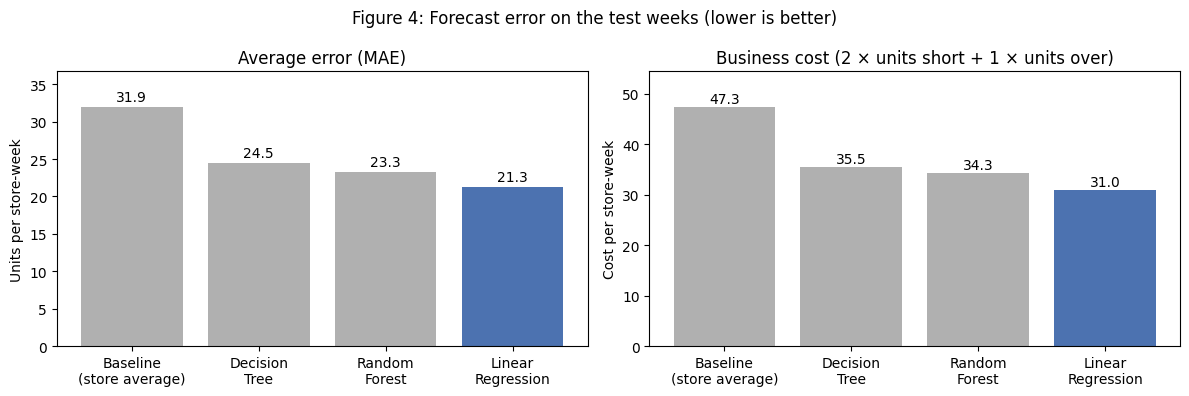

In [33]:
# Pick the order and colours for the bars, highlighting the chosen model
chart_models = ['Baseline (store average)', 'Decision Tree', 'Random Forest', 'Linear Regression']
chart_labels = ['Baseline\n(store average)', 'Decision\nTree', 'Random\nForest', 'Linear\nRegression']
chart_colours = [OTHER_COLOUR, OTHER_COLOUR, OTHER_COLOUR, BAR_COLOUR]

# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot MAE and business cost for each model, with the value above each bar
for ax, metric in zip(axes, ['MAE', 'Business cost']):
    values = results_table.loc[chart_models, metric]
    ax.bar(chart_labels, values, color=chart_colours)
    for i, value in enumerate(values):
        ax.text(i, value + 0.8, round(value, 1), ha='center')
    ax.set_ylim(0, values.max() * 1.15)

# Add the labels and title
axes[0].set_title('Average error (MAE)')
axes[0].set_ylabel('Units per store-week')
axes[1].set_title('Business cost (2 × units short + 1 × units over)')
axes[1].set_ylabel('Cost per store-week')
fig.suptitle('Figure 4: Forecast error on the test weeks (lower is better)')
plt.tight_layout()
plt.show()

### 3.8 Accounting for the 2:1 cost with a safety buffer

A balanced forecast runs short about half the time. Because running short costs twice as much, we add a fixed number of units to every forecast. We pick that number using the training weeks only.

In [34]:
# Try buffers from 0 to 30 units and return the one with the lowest business cost
def choose_buffer(actual, predicted):
    error = actual - predicted
    costs = []
    for buffer in range(0, 31):
        units_short = (error - buffer).clip(lower=0)
        units_over = (buffer - error).clip(lower=0)
        costs.append((2 * units_short + units_over).mean())
    return int(np.argmin(costs)), costs

# Get honest forecasts for the training weeks, each made without seeing its own 2 weeks
lr_train_pred = cross_val_predict(LinearRegression(), X_train_lr, y_train, cv=folds, groups=week_groups)

# Find the best buffer for linear regression
best_buffer, lr_buffer_costs = choose_buffer(y_train, lr_train_pred)
print('Best safety buffer:', best_buffer, 'units')
print('Training cost with no buffer: ', round(lr_buffer_costs[0], 1))
print('Training cost with the buffer:', round(lr_buffer_costs[best_buffer], 1))
print('Training weeks covered by forecast + buffer:', round((y_train <= lr_train_pred + best_buffer).mean() * 100), '%')

Best safety buffer: 13 units
,Training cost with no buffer:  33.9
,Training cost with the buffer: 30.9
,Training weeks covered by forecast + buffer: 67 %


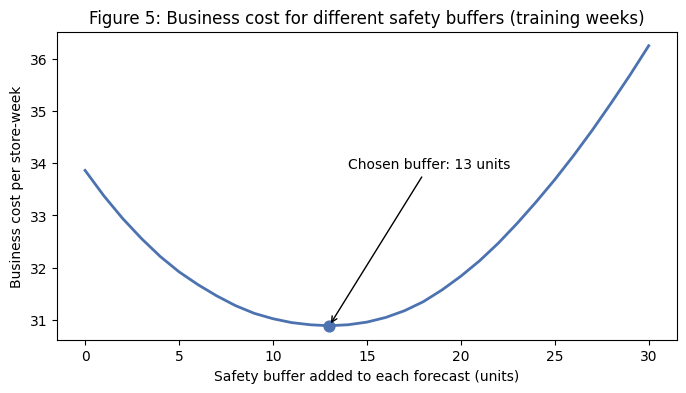

In [35]:
# Plot the business cost for each buffer size
plt.figure(figsize=(8, 4))
plt.plot(range(0, 31), lr_buffer_costs, color=BAR_COLOUR, linewidth=2)

# Mark the chosen buffer
plt.scatter(best_buffer, lr_buffer_costs[best_buffer], color=BAR_COLOUR, s=60, zorder=3)
plt.annotate('Chosen buffer: ' + str(best_buffer) + ' units',
             (best_buffer, lr_buffer_costs[best_buffer]),
             xytext=(best_buffer + 1, lr_buffer_costs[best_buffer] + 3),
             arrowprops={'arrowstyle': '->'})

# Add the labels and title
plt.xlabel('Safety buffer added to each forecast (units)')
plt.ylabel('Business cost per store-week')
plt.title('Figure 5: Business cost for different safety buffers (training weeks)')
plt.show()

In [36]:
# Add the buffer to the linear regression forecast
final_forecast = predictions['Linear Regression'] + best_buffer

# Give the store-average baseline its own best buffer too, so the comparison is fair
baseline_buffer, baseline_buffer_costs = choose_buffer(y_train, train['StoreAvg'])
print('Linear regression buffer:', best_buffer, 'units | Baseline buffer:', baseline_buffer, 'units')

# Compare each forecast with and without its buffer on the test weeks
buffer_results = [
    baseline_result,
    evaluate('Linear Regression', y_test, predictions['Linear Regression']),
    evaluate('Baseline + buffer', y_test, baseline_pred + baseline_buffer),
    evaluate('Linear Regression + buffer', y_test, final_forecast),
]
buffer_table = pd.DataFrame(buffer_results).set_index('Model')
buffer_table.round(1)

Linear regression buffer: 13 units | Baseline buffer: 19 units


,MAE,RMSE,% weeks under-forecast,Avg units short,Avg units over,Business cost
Model,,,,,,
Baseline (store average),31.9,40.6,47.3,15.4,16.6,47.3
Linear Regression,21.3,26.5,45.3,9.7,11.5,31.0
Baseline + buffer,36.5,45.3,29.7,8.2,28.4,44.7
Linear Regression + buffer,24.6,30.3,29.0,4.9,19.7,29.5


In [37]:
# Get honest training-week forecasts for every option
train_forecasts = {
    'Baseline (store average)': train['StoreAvg'],
    'Decision Tree': cross_val_predict(models['Decision Tree'], X_train, y_train, cv=folds, groups=week_groups),
    'Random Forest': cross_val_predict(models['Random Forest'], X_train, y_train, cv=folds, groups=week_groups),
    'Linear Regression': lr_train_pred,
}
test_forecasts = {
    'Baseline (store average)': baseline_pred,
    'Decision Tree': predictions['Decision Tree'],
    'Random Forest': predictions['Random Forest'],
    'Linear Regression': predictions['Linear Regression'],
}

# Give each option its own best buffer, then score it on the test weeks
fair_results = []
for name in train_forecasts:
    buffer, costs = choose_buffer(y_train, train_forecasts[name])
    result = evaluate(name, y_test, test_forecasts[name] + buffer)
    result['Buffer'] = buffer
    fair_results.append(result)

# Show the results, cheapest first
pd.DataFrame(fair_results).set_index('Model').sort_values('Business cost').round(1)

,MAE,RMSE,% weeks under-forecast,Avg units short,Avg units over,Business cost,Buffer
Model,,,,,,,
Linear Regression,24.6,30.3,29.0,4.9,19.7,29.5,13
Random Forest,26.1,32.3,31.7,5.9,20.2,31.9,13
Decision Tree,27.5,34.0,30.0,6.1,21.4,33.6,13
Baseline (store average),36.5,45.3,29.7,8.2,28.4,44.7,19


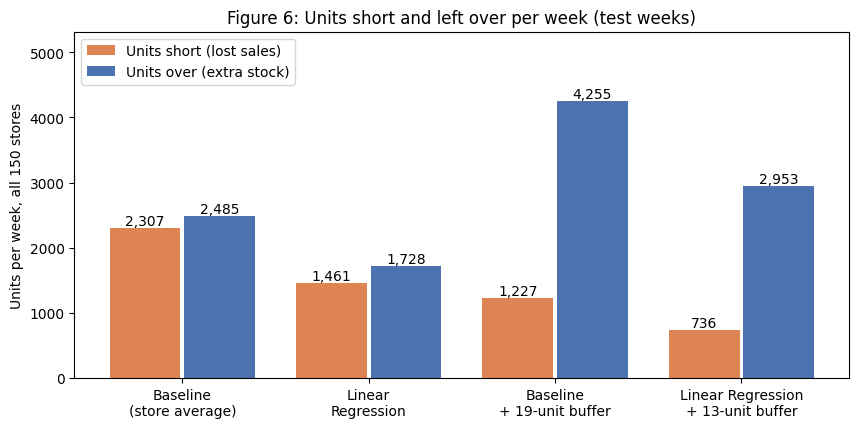

In [38]:
# Work out units short and units over per week across all 150 stores
store_count = df['StoreID'].nunique()
short_per_week = buffer_table['Avg units short'] * store_count
over_per_week = buffer_table['Avg units over'] * store_count

# Plot units short and units over side by side for each forecast
labels = ['Baseline\n(store average)', 'Linear\nRegression',
          'Baseline\n+ ' + str(baseline_buffer) + '-unit buffer',
          'Linear Regression\n+ ' + str(best_buffer) + '-unit buffer']
x = np.arange(len(labels))
plt.figure(figsize=(10, 4.5))
plt.bar(x - 0.2, short_per_week, width=0.38, color=SHORT_COLOUR, label='Units short (lost sales)')
plt.bar(x + 0.2, over_per_week, width=0.38, color=BAR_COLOUR, label='Units over (extra stock)')

# Add the value above each bar
for i in range(len(labels)):
    plt.text(x[i] - 0.2, short_per_week.iloc[i] + 40, format(round(short_per_week.iloc[i]), ','), ha='center')
    plt.text(x[i] + 0.2, over_per_week.iloc[i] + 40, format(round(over_per_week.iloc[i]), ','), ha='center')

# Add the labels and title
plt.xticks(x, labels)
plt.ylabel('Units per week, all 150 stores')
plt.title('Figure 6: Units short and left over per week (test weeks)')
plt.ylim(0, over_per_week.max() * 1.25)
plt.legend(loc='upper left')
plt.show()

In [39]:
# Check how often the final forecast runs short in each type of promotion week
check = test[['Display', 'Media']].copy()
check['Ran short'] = y_test > final_forecast
short_by_promo = check.groupby(['Display', 'Media'])['Ran short'].agg(['mean', 'count'])
short_by_promo['mean'] = (short_by_promo['mean'] * 100).round(1)
short_by_promo.columns = ['% weeks short', 'Store-weeks']
short_by_promo

% weeks short  Store-weeks
Display Media                            
0       0               28.8          146
        1               34.0           53
1       0               26.0           77
        1               29.2           24

In [40]:
# Check how often the final forecast runs short for small, mid-sized and large stores
check['Store size'] = pd.qcut(test['StoreID'].map(store_sales), 3, labels=['Small', 'Mid-sized', 'Large'])
short_by_size = check.groupby('Store size', observed=True)['Ran short'].agg(['mean', 'count'])
short_by_size['mean'] = (short_by_size['mean'] * 100).round(1)
short_by_size.columns = ['% weeks short', 'Store-weeks']
short_by_size

,% weeks short,Store-weeks
Store size,,
Small,34.0,100
Mid-sized,26.0,100
Large,27.0,100


### 3.9 What drives sales?

In [41]:
# Use linear regression as the final model
final_model = models['Linear Regression']

# Show how many units each feature adds or removes, holding the others fixed
meaning = ['per extra dollar of price', 'display vs no display', 'media vs no media']
coefficients = pd.DataFrame({
    'Feature': features,
    'Effect on weekly sales (units)': final_model.coef_[:3].round(1),
    'Meaning': meaning,
})

# Show how far apart the stores sit once price and promotions are held fixed
typical_week = test.drop_duplicates('StoreID').assign(Price=df['Price'].median(), Display=0, Media=0)
store_levels = final_model.predict(store_columns(typical_week, features, store_list))
print('Store levels at the median price with no promotion:', round(store_levels.min()), 'to',
      round(store_levels.max()), 'units')
coefficients

Store levels at the median price with no promotion: 169 to 269 units


,Feature,Effect on weekly sales (units),Meaning
0,Price,-8.9,per extra dollar of price
1,Display,41.6,display vs no display
2,Media,31.2,media vs no media


Which store it is    8.9
,Display              8.5
,Price                7.8
,Media                4.7
,dtype: float64


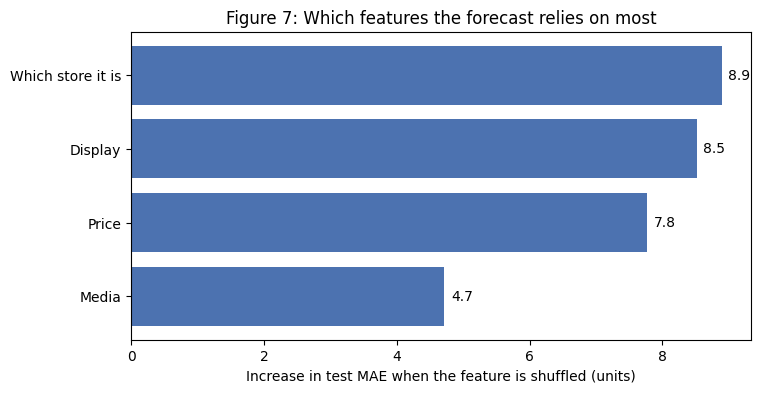

In [42]:
# Shuffle each input 20 times and measure how much worse the test MAE gets
rng = np.random.default_rng(42)
test_mae = (y_test - predictions['Linear Regression']).abs().mean()
importance = {}
for column in features + ['StoreID']:
    increases = []
    for repeat in range(20):
        shuffled = test.copy()
        shuffled[column] = rng.permutation(shuffled[column].values)
        shuffled_pred = final_model.predict(store_columns(shuffled, features, store_list))
        increases.append((y_test - shuffled_pred).abs().mean() - test_mae)
    importance[column] = np.mean(increases)
importance_table = pd.Series(importance).sort_values()
importance_table = importance_table.rename({'StoreID': 'Which store it is'})
print(importance_table.sort_values(ascending=False).round(1))

# Plot the importance of each feature, biggest at the top
plt.figure(figsize=(8, 4))
plt.barh(importance_table.index, importance_table.values, color=BAR_COLOUR)

# Add the value at the end of each bar
for i, value in enumerate(importance_table.values):
    plt.text(value + 0.1, i, round(value, 1), va='center')

# Add the labels and title
plt.xlabel('Increase in test MAE when the feature is shuffled (units)')
plt.title('Figure 7: Which features the forecast relies on most')
plt.show()

### 3.10 Extra checks

In [43]:
# Work out what price cut gives the same lift as a display or media
effects = dict(zip(X_train_lr.columns, final_model.coef_))
units_per_dollar = -effects['Price']
print('Units lost per extra $1 of price:', round(units_per_dollar, 1))
print('A display is worth the same as a price cut of $', round(effects['Display'] / units_per_dollar, 2))
print('Media is worth the same as a price cut of $', round(effects['Media'] / units_per_dollar, 2))

Units lost per extra $1 of price: 8.9
,A display is worth the same as a price cut of $ 4.67
,Media is worth the same as a price cut of $ 3.51


In [44]:
# Add a column that is 1 only when a display and media run in the same week
X_train_combo = X_train_lr.assign(DisplayAndMedia=X_train_lr['Display'] * X_train_lr['Media'])
X_test_combo = X_test_lr.assign(DisplayAndMedia=X_test_lr['Display'] * X_test_lr['Media'])

# Refit linear regression with the extra column and compare
combo_model = LinearRegression().fit(X_train_combo, y_train)
combo_effects = dict(zip(X_train_combo.columns, combo_model.coef_))
combo_mae = (y_test - combo_model.predict(X_test_combo)).abs().mean()
print('Extra units when display and media run together:', round(combo_effects['DisplayAndMedia'], 1))
print('Test MAE without the combo column:', round(results_table.loc['Linear Regression', 'MAE'], 1))
print('Test MAE with the combo column:   ', round(combo_mae, 1))

Extra units when display and media run together: -0.9
,Test MAE without the combo column: 21.3
,Test MAE with the combo column:    21.3


In [45]:
# Refit linear regression with StoreAvg instead of the store columns
store_avg_model = LinearRegression().fit(X_train, y_train)
store_avg_mae = (y_test - store_avg_model.predict(X_test)).abs().mean()

# Refit it with no store information at all, which is what a brand-new store would get
no_store_model = LinearRegression().fit(train[features], y_train)
no_store_mae = (y_test - no_store_model.predict(test[features])).abs().mean()

# Compare against one chain-wide average for every store
chain_avg_mae = (y_test - y_train.mean()).abs().mean()

# Print the results
print('Linear regression with store columns:       ', round(results_table.loc['Linear Regression', 'MAE'], 1))
print('Linear regression with StoreAvg instead:    ', round(store_avg_mae, 1))
print('Linear regression with no store information:', round(no_store_mae, 1), '(fallback for a new store)')
print('Baseline (store average):                   ', round(results_table.loc['Baseline (store average)', 'MAE'], 1))
print('One chain-wide average:                     ', round(chain_avg_mae, 1))

Linear regression with store columns:        21.3
,Linear regression with StoreAvg instead:     22.3
,Linear regression with no store information: 25.5 (fallback for a new store)
,Baseline (store average):                    31.9
,One chain-wide average:                      34.1


In [46]:
# Check whether adding Week back in would help, using the training weeks only
with_week_train = store_columns(train, features + ['Week'], store_list)
with_week_pred = cross_val_predict(LinearRegression(), with_week_train, y_train, cv=folds, groups=week_groups)
week_effect = LinearRegression().fit(with_week_train, y_train).coef_[3]

# Print the results
print('Cross-validated MAE without Week:', round((y_train - lr_train_pred).abs().mean(), 1))
print('Cross-validated MAE with Week:   ', round((y_train - with_week_pred).abs().mean(), 1))
print('Week effect:', round(week_effect, 2), 'units per week')
print('Shift this adds to a week-52 forecast, compared with week 8:', round(week_effect * (52 - 8), 1), 'units')

Cross-validated MAE without Week: 22.6
,Cross-validated MAE with Week:    22.5
,Week effect: -0.62 units per week
,Shift this adds to a week-52 forecast, compared with week 8: -27.4 units


In [47]:
# Repeat the comparison on a random 80/20 split as a robustness check
random_train, random_test = train_test_split(df, test_size=0.2, random_state=42)
random_train, random_test = add_store_average(random_train, random_test)

# Build each model's inputs for the random split
random_stores = sorted(random_train['StoreID'].unique())
random_inputs = {
    'Linear Regression': (store_columns(random_train, features, random_stores),
                          store_columns(random_test, features, random_stores)),
    'Decision Tree': (random_train[tree_features], random_test[tree_features]),
    'Random Forest': (random_train[tree_features], random_test[tree_features]),
}

# Score the baseline and a fresh copy of each model on the random split
random_results = [evaluate('Baseline (store average)', random_test['Sales'], random_test['StoreAvg'])]
for name, model in models.items():
    train_inputs, test_inputs = random_inputs[name]
    random_model = clone(model).fit(train_inputs, random_train['Sales'])
    random_results.append(evaluate(name, random_test['Sales'], random_model.predict(test_inputs)))

# Show the results table
pd.DataFrame(random_results).set_index('Model').round(1)

,MAE,RMSE,% weeks under-forecast,Avg units short,Avg units over,Business cost
Model,,,,,,
Baseline (store average),32.7,40.9,52.0,16.3,16.5,49.0
Linear Regression,22.6,27.9,50.0,11.8,10.8,34.4
Decision Tree,25.3,31.6,50.0,12.7,12.6,38.0
Random Forest,24.2,30.0,50.3,12.5,11.7,36.8


### 3.11 Impact across 150 stores

In [48]:
# Get the results for each forecast
before = buffer_table.loc['Baseline (store average)']
before_buffered = buffer_table.loc['Baseline + buffer']
model_only = buffer_table.loc['Linear Regression']
after = buffer_table.loc['Linear Regression + buffer']
avg_price = df['Price'].mean()

# Overall change from today's store-average method to the new forecast with its buffer
print('TOTAL CHANGE: store average -> linear regression +', best_buffer, 'unit buffer')
print('Average error per store-week:', round(before['MAE'], 1), '->', round(after['MAE'], 1), 'units')
print('Business cost per store-week:', round(before['Business cost'], 1), '->', round(after['Business cost'], 1))
print('Units short per week (all stores):', round(before['Avg units short'] * store_count), '->',
      round(after['Avg units short'] * store_count))
print('Units over per week (all stores): ', round(before['Avg units over'] * store_count), '->',
      round(after['Avg units over'] * store_count))

# Split the lost sales avoided into the part from the model and the part from the buffer
total_units = (before['Avg units short'] - after['Avg units short']) * store_count
print('Lost sales avoided per week:', round(total_units), 'units')
print('  from the model alone:', round((before['Avg units short'] - model_only['Avg units short']) * store_count), 'units')
print('  from the buffer:     ', round((model_only['Avg units short'] - after['Avg units short']) * store_count), 'units')

# Fair comparison: give today's method its own buffer too, so only the model's improvement is left
model_units = (before_buffered['Avg units short'] - after['Avg units short']) * store_count
print()
print('MODEL ONLY: store average +', baseline_buffer, 'unit buffer -> linear regression +', best_buffer, 'unit buffer')
print('Business cost per store-week:', round(before_buffered['Business cost'], 1), '->', round(after['Business cost'], 1))
print('Fewer units short per week:', round(model_units))
print('Fewer units over per week: ', round((before_buffered['Avg units over'] - after['Avg units over']) * store_count))

# Turn lost sales into revenue, assuming every unit short is a lost sale at the average price
print()
print('REVENUE KEPT (not profit), assuming each unit short is a lost sale at $' + str(round(avg_price, 2)),
      'and the 2 test weeks are typical')
print('Total change: about $' + format(round(total_units * avg_price, -2), ',.0f'), 'a week,',
      'or about $' + format(round(total_units * avg_price * 52, -4), ',.0f'), 'a year')
print('Model only:   about $' + format(round(model_units * avg_price, -2), ',.0f'), 'a week,',
      'or about $' + format(round(model_units * avg_price * 52, -4), ',.0f'), 'a year')

TOTAL CHANGE: store average -> linear regression + 13 unit buffer
,Average error per store-week: 31.9 -> 24.6 units
,Business cost per store-week: 47.3 -> 29.5
,Units short per week (all stores): 2307 -> 736
,Units over per week (all stores):  2485 -> 2953
,Lost sales avoided per week: 1571 units
,  from the model alone: 846 units
,  from the buffer:      725 units
,
,MODEL ONLY: store average + 19 unit buffer -> linear regression + 13 unit buffer
,Business cost per store-week: 44.7 -> 29.5
,Fewer units short per week: 491
,Fewer units over per week:  1302
,
,REVENUE KEPT (not profit), assuming each unit short is a lost sale at $11.98 and the 2 test weeks are typical
,Total change: about $18,800 a week, or about $980,000 a year
,Model only:   about $5,900 a week, or about $310,000 a year
